# Chapitre 11 - Cours 6 : raisonner sur le temps

« La moyenne des cinq dernières minutes » : l'expression paraît limpide. Elle est en
réalité piégeuse dès que les événements arrivent en retard, dans le désordre, ou
horodatés par des horloges peu fiables. Ce notebook couvre la sous-section *Reasoning
About Time* : *Event time versus processing time*, *Knowing when you're ready*, *Whose clock
are you using, anyway?* et *Types of windows*. Les fonctions de fenêtrage et le compteur
à filigrane sont dans [`ddia/streams.py`](../../ddia/streams.py).

**Plan.**

1. Temps de l'événement contre temps de traitement.
2. Les retardataires : quand une fenêtre est-elle complète ? (filigranes)
3. L'horloge de qui ?
4. Les types de fenêtres.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

from ddia import streams as st
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Temps de l'événement contre temps de traitement (sections *Reasoning About Time* et *Event time versus processing time*)

Un traitement par lots traverse en quelques minutes une année d'événements historiques :
l'horloge de la machine qui l'exécute n'a aucun rapport avec l'époque des événements, il
utilise donc l'**horodatage contenu dans chaque événement**. Bonus : le traitement est
**déterministe**, le relancer sur la même entrée donne le même résultat.

Beaucoup de frameworks de flux utilisent au contraire l'horloge locale de la machine de
traitement, le **temps de traitement** (processing time), pour découper les fenêtres.
C'est simple, et raisonnable si le délai entre la création et le traitement d'un
événement est négligeable. Mais le traitement peut prendre du retard pour mille raisons :
files d'attente, pannes réseau, contention dans le courtier, redémarrage du consommateur,
retraitement du passé après une panne ou la correction d'un bogue. Les délais
**réordonnent** aussi les événements : un utilisateur fait une requête servie par le
serveur A, puis une autre servie par B ; si l'événement de B atteint le courtier avant
celui de A, les consommateurs les voient dans l'ordre inverse. (Le livre compare cela à
une saga cinématographique vue dans l'ordre de sortie des films, qui ne suit pas l'ordre
chronologique du récit : le numéro d'épisode est le temps de l'événement, la date de
visionnage le temps de traitement.)

Confondre les deux produit de **fausses données**. Un opérateur compte les requêtes par
seconde d'un service dont le débit réel est stable (200 par seconde en moyenne). On le
redéploie : il s'arrête une minute, puis rattrape son retard à cinq fois la vitesse
normale.

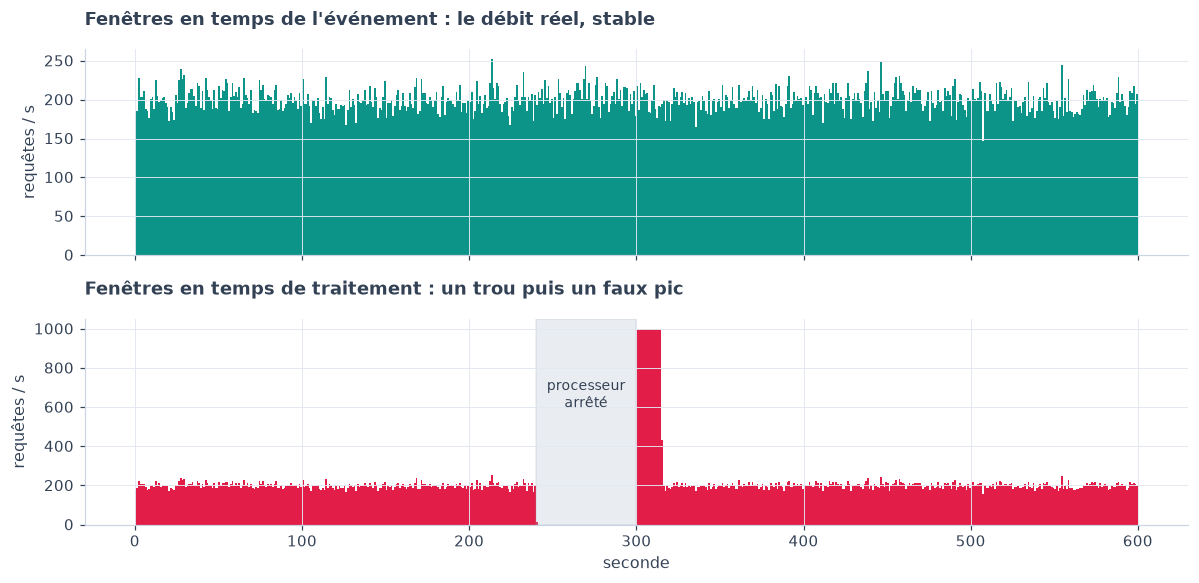

pic apparent en temps de traitement : 1000 req/s ; maximum réel : 252 req/s


In [2]:
T = 600
t_ev = np.sort(rng.uniform(0, T, 200 * T))
arret, reprise, vitesse = 240.0, 300.0, 5.0
# instant de traitement : les événements arrivés pendant l'arrêt attendent, puis la file se vide à 5x
t_tr = t_ev + 0.05
apres = t_ev >= arret
k = np.arange(apres.sum())
t_tr[apres] = np.maximum(t_ev[apres] + 0.05, reprise + k / (200 * vitesse))   # file vidée à 1 000 req/s
bins = np.arange(0, T + 1, 1)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True)
ax.hist(t_ev, bins=bins, color=TEAL)
ax.set_ylabel("requêtes / s"); ax.set_title("Fenêtres en temps de l'événement : le débit réel, stable")
ax2.hist(t_tr, bins=bins, color=ROSE)
ax2.axvspan(arret, reprise, color=GRAY, alpha=0.2)
ax2.text((arret + reprise) / 2, 600, "processeur\narrêté", ha="center", fontsize=9, color=SLATE)
ax2.set_ylabel("requêtes / s"); ax2.set_xlabel("seconde")
ax2.set_title("Fenêtres en temps de traitement : un trou puis un faux pic")
plt.tight_layout(); plt.show()
print(f"pic apparent en temps de traitement : {np.histogram(t_tr, bins)[0].max()} req/s ; "
      f"maximum réel : {np.histogram(t_ev, bins)[0].max()} req/s")

Le débit réel n'a jamais dépassé 250 requêtes par seconde ; en temps de traitement, on voit
une minute à zéro puis un pic à environ mille, deux artefacts du redéploiement. Les
fenêtres en temps de l'événement donnent la bonne réponse, et la même réponse à chaque
rejeu.

> **À retenir.** Le temps de traitement est simple mais dépend des aléas du pipeline ; le
> temps de l'événement décrit la réalité et rend le calcul déterministe. Dès qu'il peut y
> avoir du retard, il faut fenêtrer en temps de l'événement.